## Statistical Factor Modelling for Consumer Insights


Consumers choose cereals based on different preferences, such as health, taste, nutrition, and convenience. However, with 25 different product attributes, it can be difficult for cereal brands to understand what actually drives customer perceptions and how they compare with competitors.

The aim of this analysis is to use Exploratory Factor Analysis (EFA) to identify the underlying factors that explain how consumers perceive cereals. 

### Importing Libraries and Data Loading

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2, chi2_contingency, trim_mean, median_abs_deviation
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from statsmodels.multivariate.factor import Factor

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

In [40]:
rte_cereal = pd.read_csv('rte_cereal.csv')
rte_cereal.columns = rte_cereal.columns.str.strip()
rte_cereal['Brand'] = rte_cereal['Brand'].str.strip()

### Descriptive Statistics

In [42]:
def describe_psych(data):
    numeric = data.copy()
    if 'Brand' in numeric.columns:
        numeric['Brand'] = pd.Categorical(numeric['Brand']).codes + 1
    result = pd.DataFrame(index=numeric.columns)
    result['vars'] = np.arange(1, len(numeric.columns) + 1)
    result['n'] = numeric.count()
    result['mean'] = numeric.mean()
    result['sd'] = numeric.std(ddof=1)
    result['median'] = numeric.median()
    result['trimmed'] = numeric.apply(lambda s: trim_mean(s.dropna(), 0.1))
    result['mad'] = numeric.apply(lambda s: median_abs_deviation(s.dropna(), scale='normal'))
    result['min'] = numeric.min()
    result['max'] = numeric.max()
    result['range'] = result['max'] - result['min']
    result['skew'] = numeric.skew()
    result['kurtosis'] = numeric.kurt()
    result['se'] = result['sd'] / np.sqrt(result['n'])
    return result

print(describe_psych(rte_cereal))

            vars    n        mean          sd  median     trimmed         mad  min  max  range      skew  kurtosis         se
Respondent     1  235  374.808511  200.698102   315.0  375.931217  287.624830  101  639    538  0.047668 -1.575329  13.092101
Brand          2  235    6.940426    3.421379     7.0    7.005291    4.447807    1   12     11 -0.081834 -1.167240   0.223186
Filling        3  235    3.880851    0.883524     4.0    3.952381    1.482602    1    5      4 -0.551887 -0.129765   0.057635
Natural        4  235    3.782979    0.886585     4.0    3.841270    1.482602    1    5      4 -0.636098  0.489633   0.057834
Fibre          5  235    3.527660    0.996940     4.0    3.576720    1.482602    1    5      4 -0.533650 -0.135165   0.065033
Sweet          6  235    2.506383    1.122308     2.0    2.449735    1.482602    1    5      4  0.386405 -0.647300   0.073211
Easy           7  235    4.531915    0.774902     5.0    4.693122    0.000000    1    6      5 -1.802466  3.426247   0

In [44]:
vars = (rte_cereal.iloc[:, 2:27] - rte_cereal.iloc[:, 2:27].mean()) / rte_cereal.iloc[:, 2:27].std(ddof=1)

In [46]:
cor = vars.corr()
print(cor)

             Filling   Natural     Fibre     Sweet      Easy      Salt  Satisfying    Energy       Fun      Kids     Soggy  Economical    Health    Family  Calories     Plain     Crisp   Regular  \
Filling     1.000000  0.539690  0.552003  0.190400  0.236529 -0.036266    0.648507  0.636759  0.265214  0.160007 -0.059886    0.051942  0.547069  0.232876  0.047214 -0.250648  0.126501  0.420499   
Natural     0.539690  1.000000  0.652290 -0.090942  0.230948 -0.216872    0.463247  0.493542  0.081903  0.060293  0.068400    0.103161  0.688098  0.107082 -0.161674 -0.138513  0.021529  0.417638   
Fibre       0.552003  0.652290  1.000000 -0.037398  0.171722 -0.174888    0.408047  0.503731  0.062731 -0.094831 -0.041667   -0.033965  0.683984 -0.010399 -0.186542 -0.122846  0.048324  0.648376   
Sweet       0.190400 -0.090942 -0.037398  1.000000  0.131211  0.443991    0.184777  0.184961  0.327223  0.123243 -0.083752   -0.239814 -0.115622  0.043432  0.467312 -0.289559  0.262766 -0.025180   
Easy      

In [48]:
upper = cor.round(3).astype(object)
upper.values[np.triu_indices_from(upper, k=1)] = ''
print(upper)

           Filling Natural  Fibre  Sweet   Easy   Salt Satisfying Energy    Fun   Kids  Soggy Economical Health Family Calories  Plain  Crisp Regular  Sugar  Fruit Process Quality  Treat Boring  \
Filling        1.0                                                                                                                                                                                  
Natural       0.54     1.0                                                                                                                                                                          
Fibre        0.552   0.652    1.0                                                                                                                                                                   
Sweet         0.19  -0.091 -0.037    1.0                                                                                                                                                            
Easy         0.

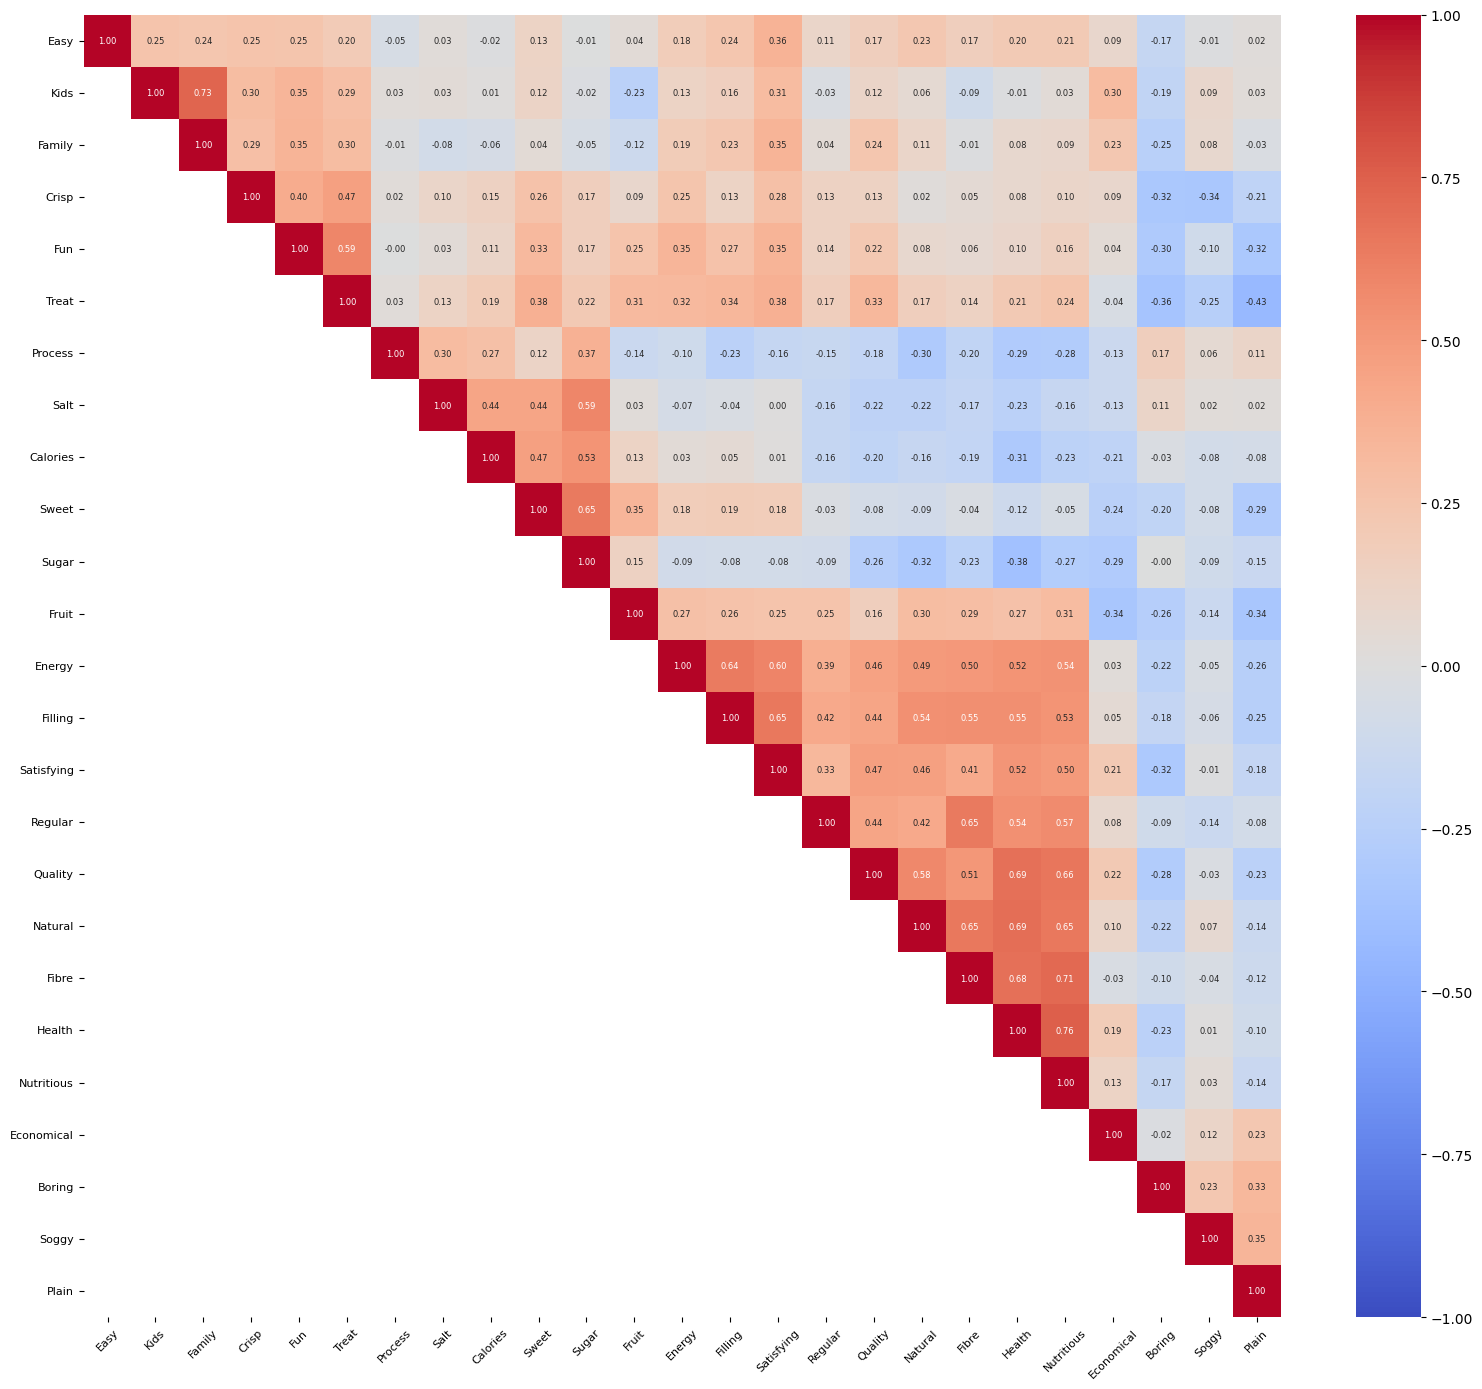

In [50]:
cluster_distances = 1 - cor.to_numpy()
np.fill_diagonal(cluster_distances, 0)
order = leaves_list(linkage(squareform(cluster_distances, checks=False), method='complete'))
ordered_cor = cor.iloc[order, order]

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    ordered_cor,
    mask=np.tril(np.ones(ordered_cor.shape, dtype=bool), k=-1),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    annot_kws={'fontsize': 6},
    ax=ax
)

ax.tick_params(axis='x', labelrotation=45, labelsize=8)
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

**Interpretation**

Health and Nutritious: Consumers who perceived a cereal as healthy also tended to consider it nutritious.

Kids and Family: Cereals associated with children were also strongly associated with family appeal.

Sweet and Sugar: Sweeter cereals were generally perceived as containing more sugar.

In [52]:
inverse_cor = np.linalg.inv(cor.to_numpy())
partial = -inverse_cor / np.sqrt(np.outer(np.diag(inverse_cor), np.diag(inverse_cor)))
np.fill_diagonal(partial, 0)

r_squared = cor.to_numpy() ** 2
np.fill_diagonal(r_squared, 0)

p_squared = partial ** 2

MSA = pd.Series(
    r_squared.sum(axis=0) / (r_squared.sum(axis=0) + p_squared.sum(axis=0)),
    index=cor.columns
)

KMO = r_squared.sum() / (r_squared.sum() + p_squared.sum())

print('Overall MSA =', round(KMO, 2))
print('MSA for each item =')
print(MSA.round(2))

Overall MSA = 0.85
MSA for each item =
Filling       0.89
Natural       0.90
Fibre         0.88
Sweet         0.78
Easy          0.83
Salt          0.82
Satisfying    0.91
Energy        0.91
Fun           0.85
Kids          0.68
Soggy         0.63
Economical    0.73
Health        0.92
Family        0.73
Calories      0.86
Plain         0.82
Crisp         0.83
Regular       0.87
Sugar         0.78
Fruit         0.77
Process       0.79
Quality       0.91
Treat         0.88
Boring        0.88
Nutritious    0.92
dtype: float64


### Testing Suitability for Factor Analysis

In [54]:
n = len(rte_cereal)
p = cor.shape[0]

chi_square = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(cor))
df = p * (p - 1) // 2
p_value = chi2.sf(chi_square, df)

print('Bartlett chi-square:', chi_square, 'p-value:', p_value, 'df:', df)

Bartlett chi-square: 2888.038399771135 p-value: 0.0 df: 300


### Eigenvalue Analysis and Factor Selection

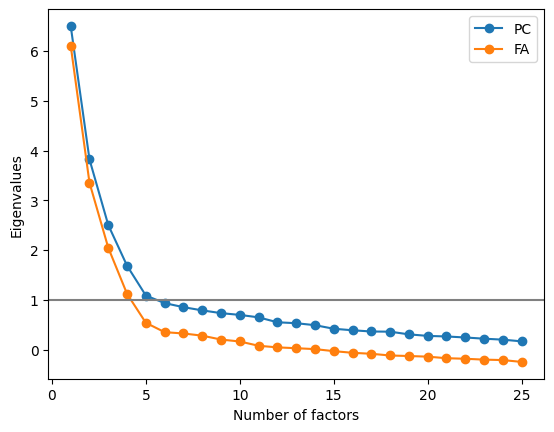

In [58]:
EV = np.linalg.eigvalsh(cor.to_numpy())[::-1]

smc = 1 - 1 / np.diag(inverse_cor)
reduced_cor = cor.to_numpy().copy()
np.fill_diagonal(reduced_cor, smc)

fa_eigenvalues = np.linalg.eigvalsh(reduced_cor)[::-1]

fig, ax = plt.subplots()
ax.plot(np.arange(1, p + 1), EV, 'o-', label='PC')
ax.plot(np.arange(1, p + 1), fa_eigenvalues, 'o-', label='FA')
ax.axhline(1, color='grey')
ax.set_xlabel('Number of factors')
ax.set_ylabel('Eigenvalues')
ax.legend()
plt.show()

### Exploratory Factor Analysis

In [61]:
print('Individual percentages of variance explained:')
print(EV / len(EV))

Individual percentages of variance explained:
[0.26017873 0.15284181 0.10007981 0.06735976 0.04341416 0.03732027
 0.03406562 0.03147346 0.02926867 0.02783403 0.02587318 0.02191834
 0.02116628 0.01958495 0.01670971 0.01548296 0.01449844 0.01435318
 0.01219016 0.01096768 0.01049792 0.00969118 0.00871902 0.00794123
 0.00656945]


In [63]:
print('Cumulative percentages of variance explained:')
print(np.cumsum(EV / len(EV)))

Cumulative percentages of variance explained:
[0.26017873 0.41302054 0.51310035 0.58046011 0.62387427 0.66119454
 0.69526016 0.72673363 0.7560023  0.78383633 0.8097095  0.83162784
 0.85279412 0.87237906 0.88908878 0.90457174 0.91907018 0.93342335
 0.94561352 0.9565812  0.96707912 0.9767703  0.98548932 0.99343055
 1.        ]


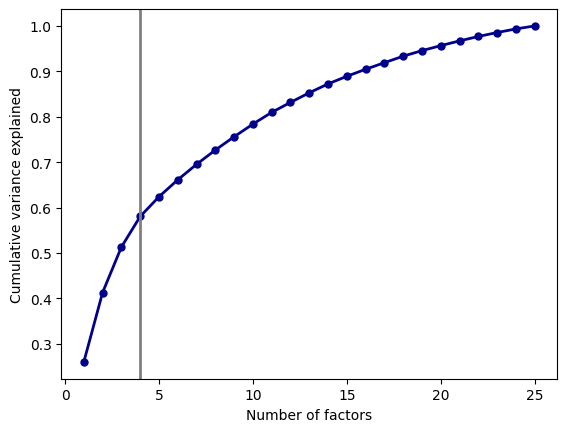

In [65]:
plt.plot(
    np.arange(1, p + 1),
    np.cumsum(EV / len(EV)),
    'o-',
    color='darkblue',
    linewidth=2,
    markersize=5
)

plt.axvline(x=4, color='grey', linewidth=2)
plt.xlabel('Number of factors')
plt.ylabel('Cumulative variance explained')
plt.show()

In [67]:
EFA1 = Factor(
    corr=cor.to_numpy(),
    n_factor=4,
    method='pa',
    nobs=n,
    endog_names=list(vars.columns)
).fit()

factor_names = ['PA1', 'PA2', 'PA3', 'PA4']

L = pd.DataFrame(
    EFA1.loadings,
    index=vars.columns,
    columns=factor_names
)

In [69]:
def print_factor_solution(loadings, cut=0.35, digits=3):
    h = (loadings ** 2).sum(axis=1)
    u = 1 - h
    com = h ** 2 / (loadings ** 4).sum(axis=1)

    display = loadings.copy()
    display[display.abs() < cut] = np.nan

    group = loadings.abs().to_numpy().argmax(axis=1)
    strength = loadings.abs().to_numpy().max(axis=1)

    idx = sorted(
        range(len(loadings)),
        key=lambda i: (group[i], -strength[i])
    )

    display = display.iloc[idx].round(digits).fillna('')
    display['h2'] = h.iloc[idx].round(digits)
    display['u2'] = u.iloc[idx].round(digits)
    display['com'] = com.iloc[idx].round(2)

    print(display)

    eig = (loadings ** 2).sum(axis=0)

    summary = pd.DataFrame(
        [
            eig,
            eig / len(loadings),
            (eig / len(loadings)).cumsum(),
            eig / eig.sum(),
            (eig / eig.sum()).cumsum()
        ],
        index=[
            'SS loadings',
            'Proportion Var',
            'Cumulative Var',
            'Proportion Explained',
            'Cumulative Proportion'
        ]
    )

    print(summary.round(digits))

print('Unrotated factor solution')
print_factor_solution(L, cut=0.35, digits=3)

Unrotated factor solution
              PA1    PA2    PA3    PA4     h2     u2   com
Health      0.813                       0.774  0.226  1.35
Nutritious  0.801                       0.728  0.272  1.28
Natural     0.731                       0.615  0.385  1.31
Quality     0.726                       0.549  0.451  1.08
Fibre       0.723                       0.703  0.297  1.72
Filling     0.721                       0.569  0.431  1.19
Satisfying  0.721                       0.606  0.394  1.35
Energy      0.698                       0.522  0.478  1.15
Regular     0.583                       0.395  0.605  1.33
Boring      -0.38                       0.337  0.663  2.93
Easy                                    0.171  0.829  2.42
Process                                 0.212  0.788  2.86
Sweet             -0.743                0.623  0.377  1.27
Sugar             -0.735                0.731  0.269  1.76
Treat       0.468 -0.567                0.590  0.410  2.27
Calories          -0.566      

In [71]:
print('Communalities in increasing order:')
print((L ** 2).sum(axis=1).sort_values())

Communalities in increasing order:
Easy          0.170621
Process       0.212011
Soggy         0.241121
Economical    0.308010
Boring        0.337247
Crisp         0.356153
Regular       0.394566
Calories      0.420222
Fruit         0.444077
Fun           0.460613
Plain         0.461145
Salt          0.485657
Energy        0.522321
Quality       0.548731
Filling       0.568573
Treat         0.589953
Family        0.594121
Satisfying    0.605800
Natural       0.614701
Sweet         0.623288
Fibre         0.702954
Kids          0.725841
Nutritious    0.728279
Sugar         0.730943
Health        0.774306
dtype: float64


In [73]:
print(L.round(3))

              PA1    PA2    PA3    PA4
Filling     0.721 -0.102 -0.067  0.184
Natural     0.731  0.239 -0.108  0.106
Fibre       0.723  0.237 -0.310  0.166
Sweet       0.085 -0.743 -0.207  0.147
Easy        0.316 -0.143  0.198  0.106
Salt       -0.208 -0.505 -0.142  0.408
Satisfying  0.721 -0.181  0.158  0.169
Energy      0.698 -0.131 -0.066  0.118
Fun         0.388 -0.492  0.206 -0.161
Kids        0.218 -0.284  0.764  0.120
Soggy      -0.097  0.225  0.147  0.399
Economical  0.150  0.230  0.471  0.102
Health      0.813  0.308 -0.111  0.080
Family      0.308 -0.218  0.671  0.026
Calories   -0.161 -0.566 -0.172  0.210
Plain      -0.309  0.360  0.223  0.432
Crisp       0.287 -0.446  0.206 -0.180
Regular     0.583  0.130 -0.182  0.069
Sugar      -0.252 -0.735 -0.254  0.250
Fruit       0.371 -0.249 -0.469 -0.154
Process    -0.300 -0.265  0.003  0.227
Quality     0.726  0.136  0.046 -0.029
Treat       0.468 -0.567  0.074 -0.210
Boring     -0.380  0.261 -0.097  0.339
Nutritious  0.801  0.217 

In [75]:
L2 = L ** 2
print(L2.round(3))

              PA1    PA2    PA3    PA4
Filling     0.520  0.010  0.004  0.034
Natural     0.534  0.057  0.012  0.011
Fibre       0.523  0.056  0.096  0.028
Sweet       0.007  0.552  0.043  0.022
Easy        0.100  0.020  0.039  0.011
Salt        0.043  0.255  0.020  0.167
Satisfying  0.520  0.033  0.025  0.028
Energy      0.487  0.017  0.004  0.014
Fun         0.150  0.242  0.042  0.026
Kids        0.047  0.081  0.584  0.014
Soggy       0.009  0.051  0.022  0.159
Economical  0.022  0.053  0.222  0.010
Health      0.661  0.095  0.012  0.006
Family      0.095  0.048  0.451  0.001
Calories    0.026  0.320  0.030  0.044
Plain       0.095  0.130  0.050  0.186
Crisp       0.082  0.199  0.043  0.032
Regular     0.340  0.017  0.033  0.005
Sugar       0.063  0.540  0.065  0.063
Fruit       0.138  0.062  0.220  0.024
Process     0.090  0.070  0.000  0.052
Quality     0.527  0.018  0.002  0.001
Treat       0.219  0.321  0.006  0.044
Boring      0.144  0.068  0.009  0.115
Nutritious  0.642  0.047 

In [77]:
h2 = L2.sum(axis=1)
print(h2.round(3))
print(h2)

Filling       0.569
Natural       0.615
Fibre         0.703
Sweet         0.623
Easy          0.171
Salt          0.486
Satisfying    0.606
Energy        0.522
Fun           0.461
Kids          0.726
Soggy         0.241
Economical    0.308
Health        0.774
Family        0.594
Calories      0.420
Plain         0.461
Crisp         0.356
Regular       0.395
Sugar         0.731
Fruit         0.444
Process       0.212
Quality       0.549
Treat         0.590
Boring        0.337
Nutritious    0.728
dtype: float64
Filling       0.568573
Natural       0.614701
Fibre         0.702954
Sweet         0.623288
Easy          0.170621
Salt          0.485657
Satisfying    0.605800
Energy        0.522321
Fun           0.460613
Kids          0.725841
Soggy         0.241121
Economical    0.308010
Health        0.774306
Family        0.594121
Calories      0.420222
Plain         0.461145
Crisp         0.356153
Regular       0.394566
Sugar         0.730943
Fruit         0.444077
Process       0.212011
Qu

In [79]:
u2 = 1 - h2
print(u2.round(3))
print(u2)

Filling       0.431
Natural       0.385
Fibre         0.297
Sweet         0.377
Easy          0.829
Salt          0.514
Satisfying    0.394
Energy        0.478
Fun           0.539
Kids          0.274
Soggy         0.759
Economical    0.692
Health        0.226
Family        0.406
Calories      0.580
Plain         0.539
Crisp         0.644
Regular       0.605
Sugar         0.269
Fruit         0.556
Process       0.788
Quality       0.451
Treat         0.410
Boring        0.663
Nutritious    0.272
dtype: float64
Filling       0.431427
Natural       0.385299
Fibre         0.297046
Sweet         0.376712
Easy          0.829379
Salt          0.514343
Satisfying    0.394200
Energy        0.477679
Fun           0.539387
Kids          0.274159
Soggy         0.758879
Economical    0.691990
Health        0.225694
Family        0.405879
Calories      0.579778
Plain         0.538855
Crisp         0.643847
Regular       0.605434
Sugar         0.269057
Fruit         0.555923
Process       0.787989
Qu

In [81]:
Eig = L2.sum(axis=0)
print(Eig.round(3))
print(EV)

PA1    6.086
PA2    3.364
PA3    2.055
PA4    1.116
dtype: float64
[6.5044682  3.8210452  2.50199528 1.68399409 1.08535397 0.93300686
 0.8516405  0.78683657 0.73171687 0.69585069 0.6468294  0.54795846
 0.52915688 0.48962363 0.41774279 0.38707401 0.362461   0.35882947
 0.30475407 0.27419206 0.26244808 0.24227943 0.2179754  0.19853087
 0.16423623]


In [83]:
print(h2.sum())
print(u2.sum())
print(h2.sum() / 25)
print((Eig / 25).round(3))

12.621255599730295
12.378744400269701
0.5048502239892119
PA1    0.243
PA2    0.135
PA3    0.082
PA4    0.045
dtype: float64


### Apply Varimax Rotation

In [85]:
EFA2 = Factor(
    corr=cor.to_numpy(),
    n_factor=4,
    method='pa',
    nobs=n,
    endog_names=list(vars.columns)
).fit()

EFA2.rotate('varimax')

L_rot = pd.DataFrame(
    EFA2.loadings,
    index=vars.columns,
    columns=factor_names
)

for factor_name, anchor in [
    ('PA1', 'Health'),
    ('PA2', 'Sugar'),
    ('PA3', 'Kids'),
    ('PA4', 'Treat')
]:
    if L_rot.loc[anchor, factor_name] < 0:
        L_rot[factor_name] *= -1

print('Varimax-rotated factor solution')
print_factor_solution(L_rot, cut=0.35, digits=3)

Varimax-rotated factor solution
              PA1    PA2    PA3    PA4     h2     u2   com
Health      0.847                       0.774  0.226  1.16
Nutritious  0.843                       0.728  0.272  1.05
Fibre       0.823                       0.703  0.297  1.08
Natural     0.766                       0.615  0.385  1.09
Filling     0.707                       0.569  0.431  1.29
Quality     0.669                       0.549  0.451  1.47
Energy      0.662                       0.522  0.478  1.40
Satisfying  0.635         0.405         0.606  0.394  1.93
Regular     0.619                       0.395  0.605  1.06
Sugar              0.814                0.731  0.269  1.21
Sweet              0.728                0.623  0.377  1.35
Salt               0.671                0.486  0.514  1.16
Calories           0.626                0.420  0.580  1.15
Process                                 0.212  0.788  2.28
Kids                      0.851         0.726  0.274  1.00
Family                  

In [87]:
weights = pd.DataFrame(
    np.linalg.solve(cor.to_numpy(), L_rot.to_numpy()),
    index=vars.columns,
    columns=factor_names
)

print('Factor score weights')
print(weights)

Factor score weights
                 PA1       PA2       PA3       PA4
Filling     0.118278  0.076449  0.012941 -0.042004
Natural     0.133376 -0.004537 -0.023844 -0.040643
Fibre       0.222471  0.076812 -0.131413 -0.088201
Sweet       0.032671  0.215855 -0.015165  0.066054
Easy        0.003831  0.013426  0.055799 -0.004450
Salt        0.013147  0.199385  0.017820 -0.146760
Satisfying  0.118838  0.078890  0.146511 -0.041412
Energy      0.075931  0.081957  0.028048  0.008264
Fun         0.011797  0.008932  0.087271  0.119437
Kids       -0.044383  0.006678  0.475301 -0.102802
Soggy       0.019014  0.039220  0.028920 -0.164013
Economical  0.003074 -0.041023  0.092372 -0.066928
Health      0.251618 -0.060146 -0.008014 -0.069412
Family     -0.005162 -0.047798  0.221274  0.008238
Calories    0.019279  0.149925 -0.007498 -0.033216
Plain       0.028777  0.063397  0.084498 -0.299931
Crisp      -0.028341 -0.008736  0.071122  0.138028
Regular     0.034123 -0.032384 -0.018783  0.027108
Sugar     

In [89]:
score_cov = weights.to_numpy().T @ cor.to_numpy() @ weights.to_numpy()

score_cor = score_cov / np.sqrt(
    np.outer(np.diag(score_cov), np.diag(score_cov))
)

print(
    pd.DataFrame(
        score_cor,
        index=factor_names,
        columns=factor_names
    ).round(3)
)

       PA1    PA2    PA3    PA4
PA1  1.000 -0.036  0.013  0.057
PA2 -0.036  1.000  0.004  0.093
PA3  0.013  0.004  1.000  0.041
PA4  0.057  0.093  0.041  1.000


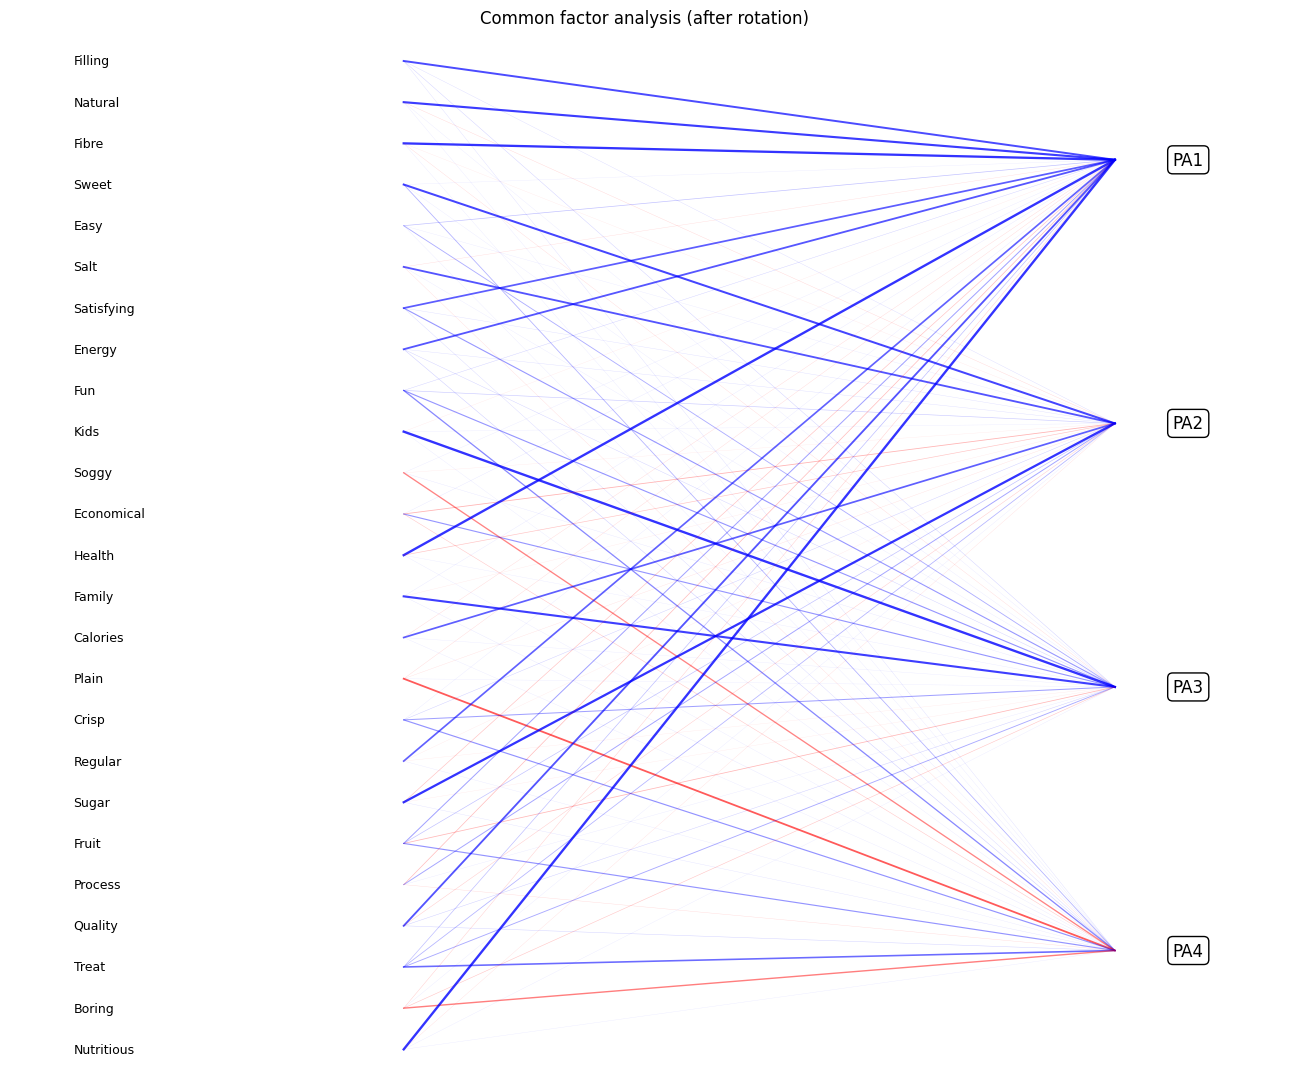

In [91]:
fig, ax = plt.subplots(figsize=(13, 11))

attribute_y = np.linspace(1, 0, len(L_rot))
factor_y = np.linspace(0.9, 0.1, 4)

for i, name in enumerate(L_rot.index):
    ax.text(0.05, attribute_y[i], name, ha='left', va='center', fontsize=9)

for j, name in enumerate(factor_names):
    ax.text(
        0.94,
        factor_y[j],
        name,
        ha='right',
        va='center',
        fontsize=12,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black')
    )

for i, name in enumerate(L_rot.index):
    for j, factor_name in enumerate(factor_names):
        value = L_rot.iloc[i, j]
        ax.plot(
            [0.31, 0.87],
            [attribute_y[i], factor_y[j]],
            color='blue' if value >= 0 else 'red',
            alpha=max(0.08, min(0.8, abs(value))),
            linewidth=max(0.3, abs(value) * 2)
        )

ax.set_title('Common factor analysis (after rotation)')
ax.set_xlim(0, 1)
ax.set_ylim(-0.03, 1.03)
ax.axis('off')

plt.tight_layout()
plt.show()

In [93]:
EFA2_scores = pd.DataFrame(
    vars.to_numpy() @ weights.to_numpy(),
    columns=factor_names,
    index=rte_cereal.index
)

print(EFA2_scores.head(6))
print(describe_psych(EFA2_scores))

        PA1       PA2       PA3       PA4
0  1.560559 -1.245350  0.149691 -1.559545
1 -2.003420 -0.809313  1.426472 -1.069161
2  1.458833  0.940766  1.050519  0.604462
3  1.676241  0.117211  0.452756  0.999791
4  0.517590 -0.690343  1.137997  1.224372
5  0.313312 -0.206790  1.414874  1.199459
     vars    n          mean        sd    median   trimmed       mad       min       max     range      skew  kurtosis        se
PA1     1  235 -1.133845e-17  0.963476  0.130964  0.049952  0.810746 -3.444995  1.713616  5.158611 -0.556584  0.304728  0.062850
PA2     2  235  3.779483e-17  0.919816 -0.120244 -0.062715  0.939677 -1.702840  3.006101  4.708941  0.586809 -0.115242  0.060002
PA3     3  235 -1.020460e-16  0.922992  0.072856  0.046127  1.028078 -2.323218  2.396316  4.719535 -0.387347 -0.394978  0.060209
PA4     4  235 -6.803069e-17  0.859444 -0.013498  0.006988  1.011808 -1.872799  1.992535  3.865334 -0.033582 -0.788588  0.056064


In [95]:
rte_cereal_scores = pd.concat(
    [rte_cereal, EFA2_scores],
    axis=1
)

print(rte_cereal_scores.head(6))

   Respondent                  Brand  Filling  Natural  Fibre  Sweet  Easy  Salt  Satisfying  Energy  Fun  Kids  Soggy  Economical  Health  Family  Calories  Plain  Crisp  Regular  Sugar  Fruit  \
0         101                Weetbix        5        5      5      1     2     1           5       4    1     4      5           5       5       5         1      3      1        4      1      1   
1         101              Special K        1        2      2      1     5     2           5       1    1     5      3           5       2       5         1      5      5        1      2      1   
2         103              Special K        5        4      5      5     5     3           5       5    5     5      3           3       5       5         1      1      5        4      3      1   
3         103          Cerola Muesli        5        5      5      3     5     2           5       5    5     5      3           3       5       5         1      1      1        4      2      5   
4         104  

In [97]:
mean_scores = rte_cereal_scores.groupby(
    'Brand',
    as_index=False,
    sort=True
)[factor_names].mean()

print(mean_scores)

                    Brand       PA1       PA2       PA3       PA4
0                All Bran  0.334390 -0.316794 -0.898030 -0.363401
1           Cerola Muesli  0.488444  0.578257 -0.247400  0.608513
2              Just Right -0.032677  0.263079 -0.419226  0.455887
3   Kellogg's Corn Flakes -0.541708  0.079804  0.591104  0.030518
4                Komplete  0.509055  0.316554 -1.025568  0.567350
5              NutriGrain -0.453412  0.795802  0.566824  0.238711
6           Purina Muesli  0.574917  0.763533 -0.425107  0.509658
7            Rice Bubbles -1.115210 -0.498730  0.635052  0.120983
8               Special K -0.287608 -0.237047  0.161366 -0.032186
9                 Sustain  0.698669 -0.194863 -0.351184  0.859674
10               Vitabrit  0.392243 -0.635835  0.207054 -0.893664
11                Weetbix  0.334602 -0.453494 -0.080336 -0.859203


In [99]:
def perceptual_map(x, y, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(9, 7))

    ax.scatter(mean_scores[x], mean_scores[y], c='blue', s=30)
    ax.axhline(0, color='grey')
    ax.axvline(0, color='grey')

    for _, row in mean_scores.iterrows():
        ax.annotate(
            row['Brand'],
            (row[x], row[y]),
            xytext=(-6, 0),
            textcoords='offset points',
            ha='right',
            va='center',
            color='black'
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)

    plt.tight_layout()
    plt.show()

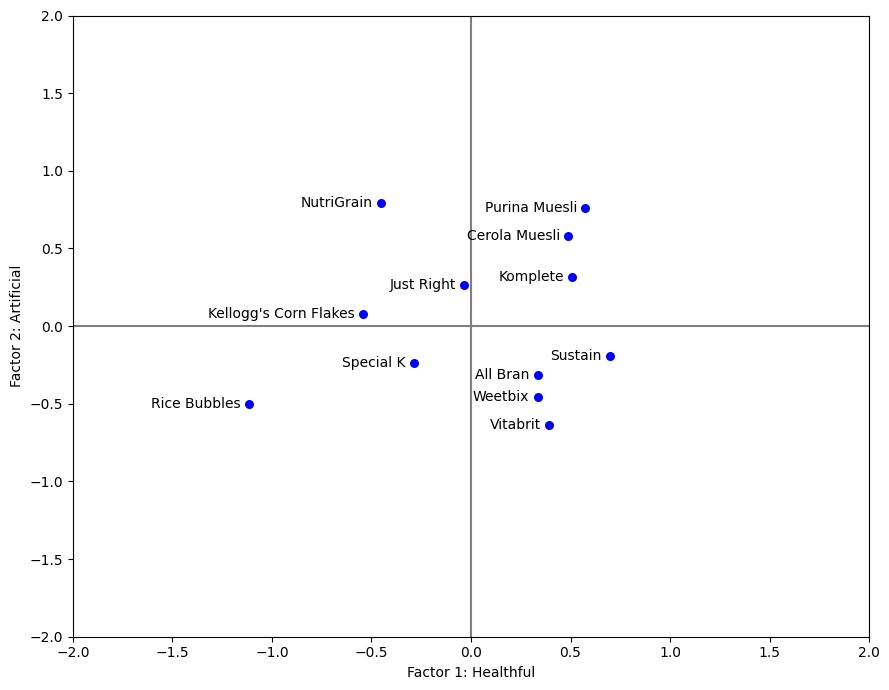

In [101]:
perceptual_map(
    'PA1',
    'PA2',
    'Factor 1: Healthful',
    'Factor 2: Artificial'
)

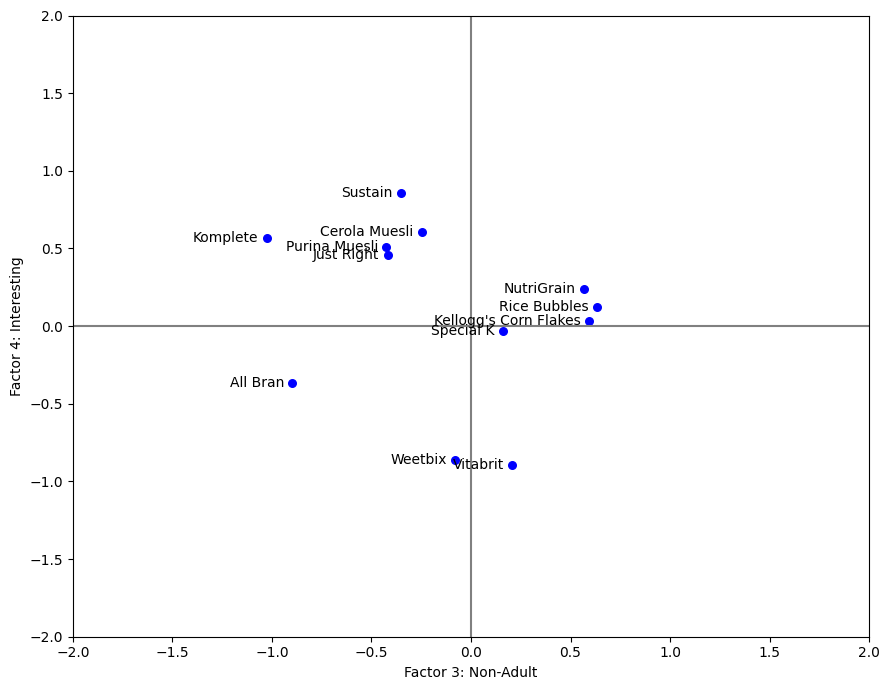

In [103]:
perceptual_map(
    'PA3',
    'PA4',
    'Factor 3: Non-Adult',
    'Factor 4: Interesting'
)

### Business Implications

### Insight 1: Health and Nutrition Form a Strong Consumer Perception Dimension

Health, Nutritious, Fibre, and Natural showed strong positive loadings on Factor 1 (approximately 0.75–0.83 after rotation).

**Business Recommendation:** Brands positioned strongly on this dimension could emphasize nutritional benefits, fibre content, and natural ingredients in their marketing. Brands with weaker health-related perceptions could investigate whether product reformulation or clearer communication would improve their positioning.

### Insight 2: Sweetness and Perceived Artificiality Are Closely Related

Sugar (loading ≈ 0.82), Sweet (≈ 0.70), Salt (≈ 0.69), and Calories (≈ 0.63) were strongly associated with Factor 2.

**Business Recommendation:** Brands should understand whether their target customers prefer indulgent cereals or place greater importance on nutritional benefits. Product positioning should reflect the intended audience rather than assuming that all consumers prefer healthier products.

### Insight 3: Children's Appeal Represents a Distinct Positioning Opportunity

Kids (loading ≈ 0.85) and Family (≈ 0.76) were strongly associated with Factor 3. These attributes were also positively correlated (r ≈ 0.73).

**Business Recommendation:** Brands seeking family-oriented positioning could explore household-focused messaging, packaging, convenience, and value propositions. The results indicate that family appeal is a recognizable perception dimension, although they do not establish its effect on sales.

### Insight 4: Product Enjoyment Provides Another Way to Differentiate Cereal Brands

Factor 4 was positively associated with Treat (≈ 0.60), Fun (≈ 0.48), and Crisp (≈ 0.44), and negatively associated with Plain (≈ −0.66) and Boring (≈ −0.51).

**Business Recommendation:** Brands positioned strongly on this dimension could focus on taste experience, texture, and enjoyment in their marketing, particularly when differentiating themselves from cereals perceived as plain or boring.

### Final Takeaway

The analysis shows that cereal brands can simplify complex customer perception data into four meaningful dimensions to better understand their competitive positioning.

Rather than evaluating all 25 product attributes separately, marketing teams can use these underlying dimensions to assess how their brands are perceived, identify areas of differentiation, and develop more focused brand strategies.

However, because the four factors explain approximately 50.5% of the total variance, and the dataset measures consumer perceptions the findings should guide further marketing research rather than be treated as proof of what drives sales.

### Insight 1: Health and Nutrition Form a Strong Consumer Perception Dimension

Health, Nutritious, Fibre, and Natural showed strong positive loadings on Factor 1 (approximately 0.75–0.83 after rotation).

**Business Recommendation:** Brands positioned strongly on this dimension could emphasize nutritional benefits, fibre content, and natural ingredients in their marketing. Brands with weaker health-related perceptions could investigate whether product reformulation or clearer communication would improve their positioning.

### Insight 2: Sweetness and Perceived Artificiality Are Closely Related

Sugar (loading ≈ 0.82), Sweet (≈ 0.70), Salt (≈ 0.69), and Calories (≈ 0.63) were strongly associated with Factor 2.

**Business Recommendation:** Brands should understand whether their target customers prefer indulgent cereals or place greater importance on nutritional benefits. Product positioning should reflect the intended audience rather than assuming that all consumers prefer healthier products.

### Insight 3: Children's Appeal Represents a Distinct Positioning Opportunity

Kids (loading ≈ 0.85) and Family (≈ 0.76) were strongly associated with Factor 3. These attributes were also positively correlated (r ≈ 0.73).

**Business Recommendation:** Brands seeking family-oriented positioning could explore household-focused messaging, packaging, convenience, and value propositions. The results indicate that family appeal is a recognizable perception dimension, although they do not establish its effect on sales.

### Insight 4: Product Enjoyment Provides Another Way to Differentiate Cereal Brands

Factor 4 was positively associated with Treat (≈ 0.60), Fun (≈ 0.48), and Crisp (≈ 0.44), and negatively associated with Plain (≈ −0.66) and Boring (≈ −0.51).

**Business Recommendation:** Brands positioned strongly on this dimension could focus on taste experience, texture, and enjoyment in their marketing, particularly when differentiating themselves from cereals perceived as plain or boring.

### Final Takeaway

The analysis shows that cereal brands can simplify complex customer perception data into four meaningful dimensions to better understand their competitive positioning.

Rather than evaluating all 25 product attributes separately, marketing teams can use these underlying dimensions to assess how their brands are perceived, identify areas of differentiation, and develop more focused brand strategies.

However, because the four factors explain approximately 50.5% of the total variance, and the dataset measures consumer perceptions the findings should guide further marketing research rather than be treated as proof of what drives sales.